In [ ]:
import pandas as pd
import os 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
from kfopenfield import behavior, utils

from DJopenfield import main
import seaborn as sb
from scipy.ndimage import gaussian_filter1d
import datasets
import etho_utils 
# Add c:\users\bramn\documents\projects\djopenfield to path
# import sys
# sys.path.append(r'C:\Users\bramn\Documents\Projects\DJOpenfield')
from etho_utils import get_escape_onsets, get_stopping_onsets, get_freezing_onsets, get_sorted_indexes


In [ ]:
drive_path = r"V:\Data\datajoint"
data_path =r"S:\Data"
ft = main.load(drive_path, data_path)

Connecting root@10.38.76.219:3306


In [3]:
exp_table = ft.Experiment()
sess_table = ft.Session()
mouse_table = ft.Mouse()
subsess_table = ft.Subsession()
condition_table = ft.Condition()

video_table = ft.behavior_tables.Video()
bodyparts_table = ft.behavior_tables.Bodyparts()
logs_table = ft.event_tables.SubsessionLogs()
trial_table = ft.behavior_tables.Trial()
trial_idx_table = ft.behavior_tables.TrialIdx()

In [ ]:
import matplotlib.colors

# colors = list(sb.color_palette(palette='tab10', n_colors=4, desat=0.75))
# colors = [colors[0], colors[-1]]
# color_sSC, color_dSC, color_LP = colors[1:]
color_sSC = matplotlib.colors.to_rgba('#de8f05')
color_dSC = matplotlib.colors.to_rgba('#029e73')
color_LP = matplotlib.colors.to_rgba('#d55e00')

# Plot colors scheme
# colors = [color_sSC, color_dSC, color_LP]
# color_CTRL, color_NTSR, color_GRP = [0.5, 0.5, 0.5, 1], [223/256, 84/256, 32/256, 1], [16/256, 122/256, 122/256, 1]
color_CTRL = matplotlib.colors.to_rgba('#949494')
color_NTSR = matplotlib.colors.to_rgba('#0173b2')
color_GRP = matplotlib.colors.to_rgba('#cc78bc')
# GRP: '#cc78bc', '#fbafe4'
# NTSR: '#0173b2', '#56b4e9'
# CTRL: '#949494'
# sb.color_palette(palette='tab10', n_colors=4, desat=1)
# Set up figure parameters


import matplotlib as mpl
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.bottom'] = True

plt.rcParams['axes.linewidth'] = 0.5
plt.rcParams['grid.linewidth'] = 0.5
plt.rcParams['lines.linewidth'] = 0.75
plt.rcParams['lines.markersize'] = 2.0
plt.rcParams['patch.linewidth'] = 1.0
plt.rcParams['xtick.major.width'] = 0.5
plt.rcParams['ytick.major.width'] = 0.5
plt.rcParams['xtick.minor.width'] = 0.5
plt.rcParams['ytick.minor.width'] = 0.5
plt.rcParams['xtick.major.size'] = 3.5
plt.rcParams['ytick.major.size'] = 3.5
plt.rcParams['xtick.minor.size'] = 2.0
plt.rcParams['ytick.minor.size'] = 2.0

mpl.rcParams['font.size'] = 8
mpl.rcParams['axes.titlesize'] = 8
mpl.rcParams['axes.labelsize'] = 8
mpl.rcParams['xtick.labelsize'] = 6
mpl.rcParams['ytick.labelsize'] = 6
mpl.rcParams['legend.fontsize'] = 6
mpl.rcParams['legend.title_fontsize'] = 6
mpl.rcParams['legend.fontsize'] = 6

mpl.rcParams['font.family'] = "sans-serif"
mpl.rcParams['font.sans-serif'] = "Arial"
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

cm = 1/2.54 # centimeters in inches

fig_path = r''
temp_data_path = r''

### Functions

### Inhibition WF vs inhibition NF vs CTRL
- Compare escape probability
- Compare stopping probability

In [5]:

ds = datasets.get_dataset('inhibition', as_keys=True)
ds.keys()

dict_keys(['NTSR_CNO', 'NTSR_CTRL_CNO', 'NTSR_CTRL_SAL', 'GRP_CNO', 'GRP_CTRL_CNO', 'GRP_CTRL_SAL'])

In [6]:
GRP_CNO_dict, GRP_CTRL_CNO_dict, GRP_CTRL_SAL_dict = ds['GRP_CNO'], ds['GRP_CTRL_CNO'], ds['GRP_CTRL_SAL']
# Combine controls
GRP_CTRL_dict = GRP_CTRL_CNO_dict + GRP_CTRL_SAL_dict

NTSR_CNO_dict, NTSR_CTRL_CNO_dict, NTSR_CTRL_SAL_dict = ds['NTSR_CNO'], ds['NTSR_CTRL_CNO'], ds['NTSR_CTRL_SAL']
# Combine controls
NTSR_CTRL_dict = NTSR_CTRL_CNO_dict + NTSR_CTRL_SAL_dict

In [7]:
len(ds['GRP_CNO']), len(ds['GRP_CTRL_CNO']), len(ds['GRP_CTRL_SAL']), len(ds['NTSR_CNO']), len(ds['NTSR_CTRL_CNO']), len(ds['NTSR_CTRL_SAL'])

(11, 7, 10, 11, 7, 5)

In [8]:
stim_types_plotting = ['EXPA', 'EXPA25', 'EXPW', 'DIMM']
stim_types_plotting_labels = ['100%\nblack looming', '25%\nblack looming', '100%\nwhite looming', 'dimming']

# Get data
def get_data(keys):
    shelter_dist_dict = {}
    speed_dict = {}
    etho_dict = {}
    # exclude_dict = {}
    for stim_type in stim_types_plotting:
        shelter_dist_dict[stim_type] = {}
        speed_dict[stim_type] = {}
        etho_dict[stim_type] = {}
        # exclude_dict[stim_type] = {}
        for key in keys:
            shelter_boundaries = etho_utils.get_shelter_boundaries(key['session_id'])

            bps, trial_ids = (trial_table*trial_idx_table & key & {'stim_type':stim_type}).fetch('bodyparts', 'trial_id', order_by='trial_idx')
            shelter_mat = []
            speed_mat = []
            etho_mat = []
            for bp, trial_id in zip(bps, trial_ids):
                d = behavior.process_dlc(pd.DataFrame.from_dict(bp).reset_index(drop=True), scheme=utils.VAME_col)
                d['measures','speed'] = gaussian_filter1d(d['measures','speed'], sigma=5)
                d['shelter_boundaries', 'x'] = shelter_boundaries[0]
                d['shelter_boundaries', 'y'] = shelter_boundaries[1]
                # Check if nose was in the shelter throughout the whole trial
                dx = np.max(np.vstack([[0]*d.shape[0], d['Nose','x']-d['shelter_boundaries', 'x']]), axis=0) # positive values are to the right of the shelter
                dy = np.max(np.vstack([[0]*d.shape[0], -1*(d['Nose','y']-d['shelter_boundaries', 'y'])]), axis=0) # positive values are above the shelter
                shelter_dist = np.sqrt(dx**2 + dy**2) 
                in_shelter = (d['Nose','x'].iloc[300:480]<shelter_boundaries[0]) & (d['Nose','y'].iloc[300:480]>shelter_boundaries[1])
                print("check:", np.sum(in_shelter), 180-np.sum(shelter_dist[300:480]>0))
                if not in_shelter.all():
                    speed_mat.append(d[('measures','speed')])
                    etho_mat.append(etho_utils.get_ethogram(d, offset=300, return_onoffs=False))
                    shelter_mat.append(shelter_dist)
                else:
                    print("------------------------- Trial excluded: Mouse {} Session {} Trial {} -------------------------".format(key['mouse_id'], key['session_id'], trial_id))

            shelter_dist_dict[stim_type][(key['experiment_id'], key['mouse_id'], key['session_id'])] = np.array(shelter_mat)
            speed_dict[stim_type][(key['experiment_id'], key['mouse_id'], key['session_id'])] = np.array(speed_mat)
            etho_dict[stim_type][(key['experiment_id'], key['mouse_id'], key['session_id'])] = np.array(etho_mat)

    return speed_dict, etho_dict, shelter_dist_dict

# get_escapes --> speed_thr=3, dur_thr=10, shelter_margin_start=[0,0], shelter_margin_end=[0,0]

In [11]:
mode = 'load' # 'load'
# Save dictionaries in temp_data folder
import pickle

if mode =='save':
    GRP_CNO_dict_speed, GRP_CNO_dict_etho, GRP_CNO_dict_shelter_dist = get_data(GRP_CNO_dict)
    GRP_CTRL_dict_speed, GRP_CTRL_dict_etho, GRP_CTRL_dict_shelter_dist = get_data(GRP_CTRL_dict)

    NTSR_CNO_dict_speed, NTSR_CNO_dict_etho, NTSR_CNO_dict_shelter_dist = get_data(NTSR_CNO_dict)
    NTSR_CTRL_dict_speed, NTSR_CTRL_dict_etho, NTSR_CTRL_dict_shelter_dist = get_data(NTSR_CTRL_dict)

    with open(os.path.join(temp_data_path, 'GRP_CNO_dict_speed.pkl'), 'wb') as f:
        pickle.dump(GRP_CNO_dict_speed, f)

    with open(os.path.join(temp_data_path, 'GRP_CNO_dict_etho.pkl'), 'wb') as f:
        pickle.dump(GRP_CNO_dict_etho, f)

    with open(os.path.join(temp_data_path, 'GRP_CNO_dict_shelter_dist.pkl'), 'wb') as f:
        pickle.dump(GRP_CNO_dict_shelter_dist, f)

    with open(os.path.join(temp_data_path, 'GRP_CTRL_dict_speed.pkl'), 'wb') as f:
        pickle.dump(GRP_CTRL_dict_speed, f)

    with open(os.path.join(temp_data_path, 'GRP_CTRL_dict_etho.pkl'), 'wb') as f:
        pickle.dump(GRP_CTRL_dict_etho, f)

    with open(os.path.join(temp_data_path, 'GRP_CTRL_dict_shelter_dist.pkl'), 'wb') as f:
        pickle.dump(GRP_CTRL_dict_shelter_dist, f)

    with open(os.path.join(temp_data_path, 'NTSR_CNO_dict_speed.pkl'), 'wb') as f:
        pickle.dump(NTSR_CNO_dict_speed, f)

    with open(os.path.join(temp_data_path, 'NTSR_CNO_dict_etho.pkl'), 'wb') as f:
        pickle.dump(NTSR_CNO_dict_etho, f)

    with open(os.path.join(temp_data_path, 'NTSR_CNO_dict_shelter_dist.pkl'), 'wb') as f:
        pickle.dump(NTSR_CNO_dict_shelter_dist, f)

    with open(os.path.join(temp_data_path, 'NTSR_CTRL_dict_speed.pkl'), 'wb') as f:
        pickle.dump(NTSR_CTRL_dict_speed, f)

    with open(os.path.join(temp_data_path, 'NTSR_CTRL_dict_etho.pkl'), 'wb') as f:
        pickle.dump(NTSR_CTRL_dict_etho, f)

    with open(os.path.join(temp_data_path, 'NTSR_CTRL_dict_shelter_dist.pkl'), 'wb') as f:
        pickle.dump(NTSR_CTRL_dict_shelter_dist, f)

    
if mode =='load':
    with open(os.path.join(temp_data_path, 'GRP_CNO_dict_speed.pkl'), 'rb') as f:
        GRP_CNO_dict_speed = pickle.load(f)

    with open(os.path.join(temp_data_path, 'GRP_CNO_dict_etho.pkl'), 'rb') as f:
        GRP_CNO_dict_etho = pickle.load(f)

    with open(os.path.join(temp_data_path, 'GRP_CNO_dict_shelter_dist.pkl'), 'rb') as f:
        GRP_CNO_dict_shelter_dist = pickle.load(f)

    with open(os.path.join(temp_data_path, 'GRP_CTRL_dict_speed.pkl'), 'rb') as f:
        GRP_CTRL_dict_speed = pickle.load(f)

    with open(os.path.join(temp_data_path, 'GRP_CTRL_dict_etho.pkl'), 'rb') as f:
        GRP_CTRL_dict_etho = pickle.load(f)

    with open(os.path.join(temp_data_path, 'GRP_CTRL_dict_shelter_dist.pkl'), 'rb') as f:
        GRP_CTRL_dict_shelter_dist = pickle.load(f)

    with open(os.path.join(temp_data_path, 'NTSR_CNO_dict_speed.pkl'), 'rb') as f:
        NTSR_CNO_dict_speed = pickle.load(f)

    with open(os.path.join(temp_data_path, 'NTSR_CNO_dict_etho.pkl'), 'rb') as f:
        NTSR_CNO_dict_etho = pickle.load(f)

    with open(os.path.join(temp_data_path, 'NTSR_CNO_dict_shelter_dist.pkl'), 'rb') as f:
        NTSR_CNO_dict_shelter_dist = pickle.load(f)

    with open(os.path.join(temp_data_path, 'NTSR_CTRL_dict_speed.pkl'), 'rb') as f:
        NTSR_CTRL_dict_speed = pickle.load(f)

    with open(os.path.join(temp_data_path, 'NTSR_CTRL_dict_etho.pkl'), 'rb') as f:
        NTSR_CTRL_dict_etho = pickle.load(f)

    with open(os.path.join(temp_data_path, 'NTSR_CTRL_dict_shelter_dist.pkl'), 'rb') as f:
        NTSR_CTRL_dict_shelter_dist = pickle.load(f)


### HEATMAPS

In [12]:
GRP_CNO_dict_speed_mat = []
GRP_CNO_dict_etho_mat = []
GRP_CNO_dict_shelter_dist_mat = []
GRP_CNO_dict_exp_ids = []
for stim_type, stim_label in zip(stim_types_plotting, stim_types_plotting_labels):
    GRP_CNO_dict_speed_mat.append(np.concatenate([value for value in GRP_CNO_dict_speed[stim_type].values()], axis=0))
    GRP_CNO_dict_etho_mat.append(np.concatenate([value for value in GRP_CNO_dict_etho[stim_type].values()], axis=0))
    GRP_CNO_dict_shelter_dist_mat.append(np.concatenate([value for value in GRP_CNO_dict_shelter_dist[stim_type].values()], axis=0))
    GRP_CNO_dict_exp_ids.append(np.concatenate([[key]*len(value) for key, value in GRP_CNO_dict_shelter_dist[stim_type].items()], axis=0))
    

GRP_CTRL_dict_speed_mat = []
GRP_CTRL_dict_etho_mat = []
GRP_CTRL_dict_shelter_dist_mat = []
GRP_CTRL_dict_exp_ids = []
for stim_type, stim_label in zip(stim_types_plotting, stim_types_plotting_labels):
    GRP_CTRL_dict_speed_mat.append(np.concatenate([value for value in GRP_CTRL_dict_speed[stim_type].values()], axis=0))
    GRP_CTRL_dict_etho_mat.append(np.concatenate([value for value in GRP_CTRL_dict_etho[stim_type].values()], axis=0))
    GRP_CTRL_dict_shelter_dist_mat.append(np.concatenate([value for value in GRP_CTRL_dict_shelter_dist[stim_type].values()], axis=0))
    GRP_CTRL_dict_exp_ids.append(np.concatenate([[key]*len(value) for key, value in GRP_CTRL_dict_shelter_dist[stim_type].items()], axis=0))

NTSR_CNO_dict_speed_mat = []
NTSR_CNO_dict_etho_mat = []
NTSR_CNO_dict_shelter_dist_mat = []
NTSR_CNO_dict_exp_ids = []
for stim_type, stim_label in zip(stim_types_plotting, stim_types_plotting_labels):
    NTSR_CNO_dict_speed_mat.append(np.concatenate([value for value in NTSR_CNO_dict_speed[stim_type].values()], axis=0))
    NTSR_CNO_dict_etho_mat.append(np.concatenate([value for value in NTSR_CNO_dict_etho[stim_type].values()], axis=0))
    NTSR_CNO_dict_shelter_dist_mat.append(np.concatenate([value for value in NTSR_CNO_dict_shelter_dist[stim_type].values()], axis=0))
    NTSR_CNO_dict_exp_ids.append(np.concatenate([[key]*len(value) for key, value in NTSR_CNO_dict_shelter_dist[stim_type].items()], axis=0))

NTSR_CTRL_dict_speed_mat = []
NTSR_CTRL_dict_etho_mat = []
NTSR_CTRL_dict_shelter_dist_mat = []
NTSR_CTRL_dict_exp_ids = []
for stim_type, stim_label in zip(stim_types_plotting, stim_types_plotting_labels):
    NTSR_CTRL_dict_speed_mat.append(np.concatenate([value for value in NTSR_CTRL_dict_speed[stim_type].values()], axis=0))
    NTSR_CTRL_dict_etho_mat.append(np.concatenate([value for value in NTSR_CTRL_dict_etho[stim_type].values()], axis=0))
    NTSR_CTRL_dict_shelter_dist_mat.append(np.concatenate([value for value in NTSR_CTRL_dict_shelter_dist[stim_type].values()], axis=0))
    NTSR_CTRL_dict_exp_ids.append(np.concatenate([[key]*len(value) for key, value in NTSR_CTRL_dict_shelter_dist[stim_type].items()], axis=0))

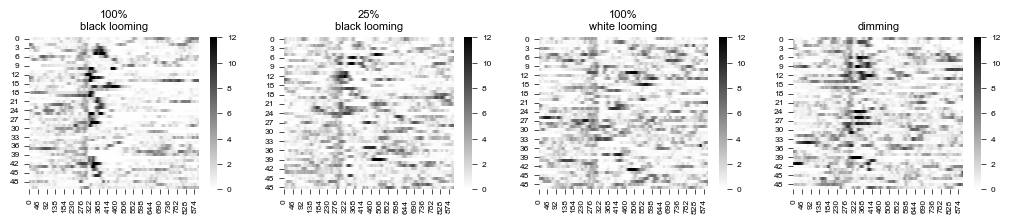

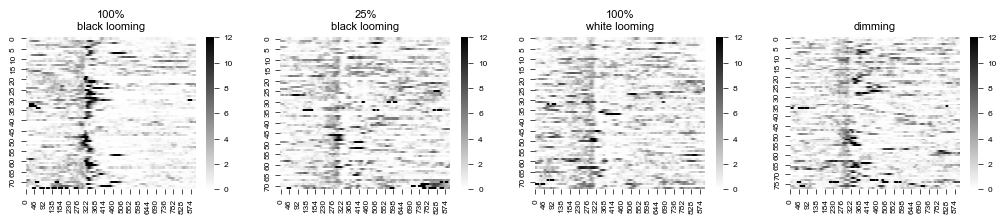

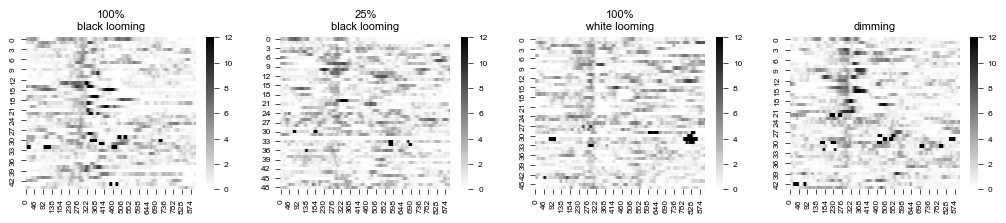

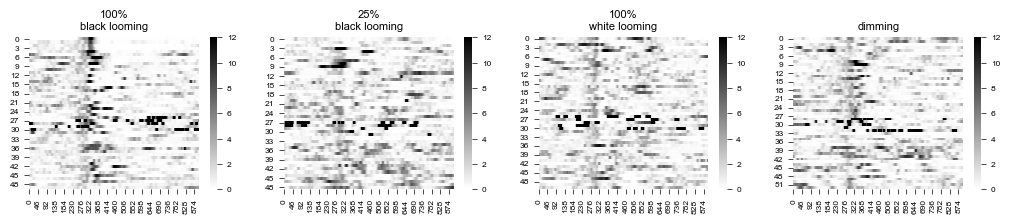

In [14]:
# --- HEATMAP UNSORTED ---
fig, axs = plt.subplots(1, len(stim_types_plotting), figsize=(len(stim_types_plotting)*8*cm, 5*cm))
for stim_label, ax, speed_mat in zip(stim_types_plotting_labels, axs, GRP_CNO_dict_speed_mat):
    sb.heatmap(speed_mat, cmap='gray_r', ax=ax, vmin=0, vmax=12)
    ax.set_title(stim_label)
plt.show()

fig, axs = plt.subplots(1, len(stim_types_plotting), figsize=(len(stim_types_plotting)*8*cm, 5*cm))
for stim_label, ax, speed_mat in zip(stim_types_plotting_labels, axs, GRP_CTRL_dict_speed_mat):
    sb.heatmap(speed_mat, cmap='gray_r', ax=ax, vmin=0, vmax=12)
    ax.set_title(stim_label)
plt.show()

fig, axs = plt.subplots(1, len(stim_types_plotting), figsize=(len(stim_types_plotting)*8*cm, 5*cm))
for stim_label, ax, speed_mat in zip(stim_types_plotting_labels, axs, NTSR_CNO_dict_speed_mat):
    sb.heatmap(speed_mat, cmap='gray_r', ax=ax, vmin=0, vmax=12)
    ax.set_title(stim_label)
plt.show()

fig, axs = plt.subplots(1, len(stim_types_plotting), figsize=(len(stim_types_plotting)*8*cm, 5*cm))
for stim_label, ax, speed_mat in zip(stim_types_plotting_labels, axs, NTSR_CTRL_dict_speed_mat):
    sb.heatmap(speed_mat, cmap='gray_r', ax=ax, vmin=0, vmax=12)
    ax.set_title(stim_label)
plt.show()

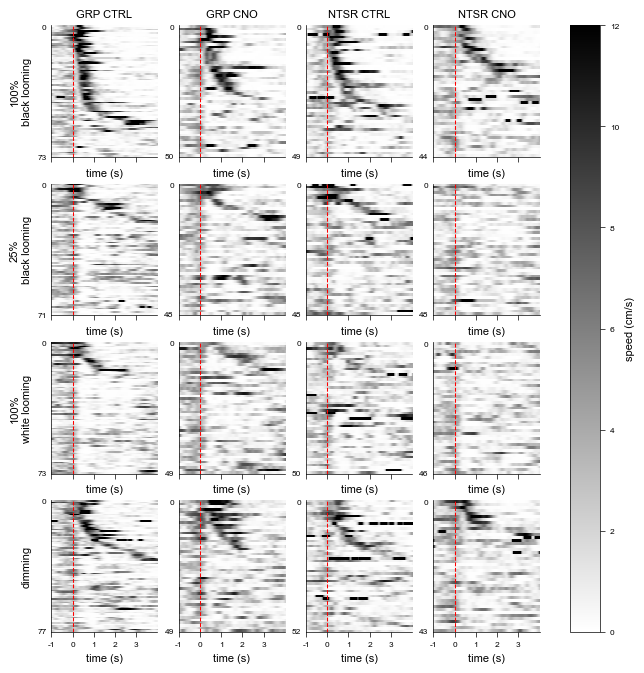

In [16]:
# --- HEATMAP SORTED BY ESCAPE ONSET ---
fig, axs = plt.subplots(len(stim_types_plotting), 4, figsize=(4*5*cm, len(stim_types_plotting)*5*cm), sharex=True)
for stim_label, ax, speed_mat, etho_mat in zip(stim_types_plotting_labels, axs[:,0], GRP_CTRL_dict_speed_mat, GRP_CTRL_dict_etho_mat):
    sorted_indexes = get_sorted_indexes(etho_mat, start=300, end=480, sort_by='escape_onset')
    # sb.heatmap(speed_mat[sorted_indexes], cmap='gray_r', ax=ax, vmin=0, vmax=12)
    # replace seaborn heatmap weith imshow
    ax.imshow(speed_mat[sorted_indexes], cmap='gray_r', vmin=0, vmax=12, aspect='auto', interpolation='none')
    ax.set(xticks=[240, 300, 360, 420, 480], xticklabels=[-1, 0, 1, 2, 3], xlabel='time (s)', yticks=[0,len(sorted_indexes)-1])
    ax.tick_params(axis='y', which='both', length=0)
    ax.axvline(x=300, color='r', linestyle='--')
    # ax.plot([5*60+0,5*60+0.5*60], [1, 1], c='k', linewidth=4, solid_capstyle='butt')
    # ax.plot([5*60+1*60,5*60+1.5*60], [1, 1], c='k', linewidth=4, solid_capstyle='butt')
    # ax.plot([5*60+2*60,5*60+2.5*60], [1, 1], c='k', linewidth=4, solid_capstyle='butt')
for stim_label, ax, speed_mat, etho_mat in zip(stim_types_plotting_labels, axs[:,1], GRP_CNO_dict_speed_mat, GRP_CNO_dict_etho_mat):
    sorted_indexes = get_sorted_indexes(etho_mat, start=300, end=480, sort_by='escape_onset')
    # sb.heatmap(speed_mat[sorted_indexes], cmap='gray_r', ax=ax, vmin=0, vmax=12)
    ax.imshow(speed_mat[sorted_indexes], cmap='gray_r', vmin=0, vmax=12, aspect='auto', interpolation='none')
    ax.set(xticks=[240, 300, 360, 420, 480], xticklabels=[-1, 0, 1, 2, 3], xlabel='time (s)', yticks=[0,len(sorted_indexes)-1])
    ax.tick_params(axis='y', which='both', length=0)
    ax.axvline(x=300, color='r', linestyle='--')

    # ax.plot([5*60+0,5*60+0.5*60], [1, 1], c='k', linewidth=4, solid_capstyle='butt')
    # ax.plot([5*60+1*60,5*60+1.5*60], [1, 1], c='k', linewidth=4, solid_capstyle='butt')
    # ax.plot([5*60+2*60,5*60+2.5*60], [1, 1], c='k', linewidth=4, solid_capstyle='butt')
    # ax.set_title(stim_label)

for stim_label, ax, speed_mat, etho_mat in zip(stim_types_plotting_labels, axs[:,2], NTSR_CTRL_dict_speed_mat, NTSR_CTRL_dict_etho_mat):
    sorted_indexes = get_sorted_indexes(etho_mat, start=300, end=480, sort_by='escape_onset')
    # sb.heatmap(speed_mat[sorted_indexes], cmap='gray_r', ax=ax, vmin=0, vmax=12)
    ax.imshow(speed_mat[sorted_indexes], cmap='gray_r', vmin=0, vmax=12, aspect='auto', interpolation='none')
    ax.set(xticks=[240, 300, 360, 420, 480], xticklabels=[-1, 0, 1, 2, 3], xlabel='time (s)', yticks=[0,len(sorted_indexes)-1])
    ax.tick_params(axis='y', which='both', length=0)

    ax.axvline(x=300, color='r', linestyle='--')

    # ax.plot([5*60+0,5*60+0.5*60], [1, 1], c='k', linewidth=4, solid_capstyle='butt')
    # ax.plot([5*60+1*60,5*60+1.5*60], [1, 1], c='k', linewidth=4, solid_capstyle='butt')
    # ax.plot([5*60+2*60,5*60+2.5*60], [1, 1], c='k', linewidth=4, solid_capstyle='butt')
    # ax.set_title(stim_label)

for stim_label, ax, speed_mat, etho_mat in zip(stim_types_plotting_labels, axs[:,3], NTSR_CNO_dict_speed_mat, NTSR_CNO_dict_etho_mat):
    sorted_indexes = get_sorted_indexes(etho_mat, start=300, end=480, sort_by='escape_onset')
    # sb.heatmap(speed_mat[sorted_indexes], cmap='gray_r', ax=ax, vmin=0, vmax=12)
    ax.imshow(speed_mat[sorted_indexes], cmap='gray_r', vmin=0, vmax=12, aspect='auto', interpolation='none')
    ax.set(xticks=[240, 300, 360, 420, 480], xticklabels=[-1, 0, 1, 2, 3], xlabel='time (s)', yticks=[0,len(sorted_indexes)-1])
    ax.tick_params(axis='y', which='both', length=0)

    ax.axvline(x=300, color='r', linestyle='--')

    # ax.plot([5*60+0,5*60+0.5*60], [-3, -3], c='k', linewidth=3, solid_capstyle='butt')
    # ax.plot([5*60+1*60,5*60+1.5*60], [-3, -3], c='k', linewidth=3, solid_capstyle='butt')
    # ax.plot([5*60+2*60,5*60+2.5*60], [-3, -3], c='k', linewidth=3, solid_capstyle='butt')
    # ax.set_title(stim_label)
axs[0,0].set(ylabel=stim_types_plotting_labels[0])
axs[1,0].set(ylabel=stim_types_plotting_labels[1])
axs[2,0].set(ylabel=stim_types_plotting_labels[2])
axs[3,0].set(ylabel=stim_types_plotting_labels[3])
axs[0,0].set(title='GRP CTRL')
axs[0,1].set(title='GRP CNO')
axs[0,2].set(title='NTSR CTRL')
axs[0,3].set(title='NTSR CNO')
axs[0,0].set(xlim=(240, 540))
fig.colorbar(axs[3,3].imshow(speed_mat[sorted_indexes], cmap='gray_r', vmin=0, vmax=12, aspect='auto', interpolation='none'), ax=axs, orientation='vertical', label='speed (cm/s)')
# plt.savefig(os.path.join(fig_path, 'fig1_inhibition_heatmaps.pdf'), bbox_inches='tight', dpi=300)
plt.show()

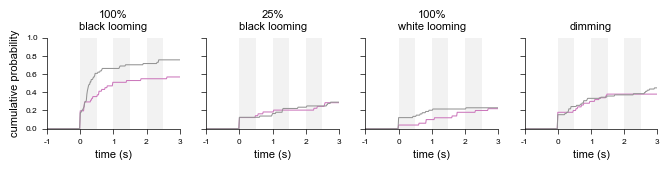

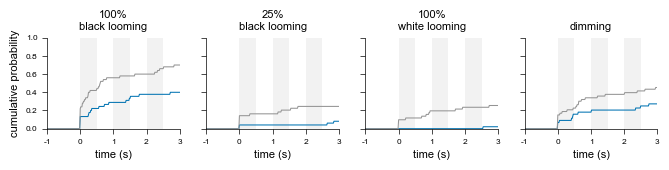

In [17]:

# --- CUMULATIVE PROBABILITY ---
def get_trace_cprob_escape(etho_mat):
    escape_onsets = get_escape_onsets(etho_mat, start=300, end=480)
    # freezing_onsets = get_freezing_onsets(etho_mat)
    # escape_onsets = freezing_onsets[(freezing_onsets!=9999)]
    # escape_onsets = freezing_onsets[(freezing_onsets!=9999)&(freezing_onsets<escape_onsets)]

    # escape_onsets = np.min([escape_onsets, freezing_onsets], axis=0)[((freezing_onsets!=9999)&(freezing_onsets>301))|((escape_onsets!=9999)&(escape_onsets>301))]
    # escape_onsets = np.min([escape_onsets, freezing_onsets], axis=0)[((freezing_onsets!=9999))|((escape_onsets!=9999))]

    escape_onsets = escape_onsets[escape_onsets!=9999]
    trace = np.zeros(etho_mat.shape[1])
    if len(escape_onsets)>0:
        for escape_onset in escape_onsets:
            trace[escape_onset] += 1
    trace_cprob = np.cumsum(trace) / len(etho_mat)
    return trace_cprob

def get_trace_cprob_freeze(etho_mat):
    escape_onsets = get_escape_onsets(etho_mat, start=300, end=480)
    freezing_onsets = get_stopping_onsets(etho_mat, start=300, end=480)
    # escape_onsets = freezing_onsets[(freezing_onsets!=9999)]
    freezing_onsets = freezing_onsets[(freezing_onsets!=9999)&(escape_onsets==9999)&(freezing_onsets>300)]

    N = np.sum(escape_onsets==9999)

    # escape_onsets = np.min([escape_onsets, freezing_onsets], axis=0)[((freezing_onsets!=9999)&(freezing_onsets>301))|((escape_onsets!=9999)&(escape_onsets>301))]
    # escape_onsets = np.min([escape_onsets, freezing_onsets], axis=0)[((freezing_onsets!=9999))|((escape_onsets!=9999))]

    # escape_onsets = escape_onsets[escape_onsets!=9999]
    trace = np.zeros(etho_mat.shape[1])
    if len(freezing_onsets)>0:
        for escape_onset in freezing_onsets:
            trace[escape_onset] += 1
    trace_cprob = np.cumsum(trace) / N
    print("trace_cprob.shape", trace_cprob.shape)
    return trace_cprob

def get_cumulative_freeze_time(etho_mat):
    escape_onsets = get_escape_onsets(etho_mat, start=300, end=480)
    freezing_onsets = get_freezing_onsets(etho_mat, start=300, end=480)
    # escape_onsets = freezing_onsets[(freezing_onsets!=9999)]
    etho_mat = etho_mat[(freezing_onsets!=9999)&(escape_onsets==9999)]

    # N = np.sum(escape_onsets==9999)

    freezing_cumulative = np.mean(np.cumsum(etho_mat[:,300:480]==3, axis=1), axis=0)
    print("freezing_cumulative.shape", freezing_cumulative.shape)
    return freezing_cumulative

def get_trial_freeze_time(etho_mat):
    escape_onsets = get_escape_onsets(etho_mat, start=300, end=480)
    freezing_onsets = get_freezing_onsets(etho_mat, start=300, end=480)
    print(len(escape_onsets), len(freezing_onsets))
    # escape_onsets = freezing_onsets[(freezing_onsets!=9999)]
    etho_mat = etho_mat[(freezing_onsets!=9999)&(escape_onsets==9999)]

    # N = np.sum(escape_onsets==9999)

    freeze_time = np.sum(etho_mat[:,300:480]==3, axis=1)
    print("freezing_time.shape", freeze_time.shape)
    return freeze_time

def get_trial_shelter_time(etho_mat, shelter_mat):
    # 1. find first escape events
    shelter_times = []
    escape_onsets = get_escape_onsets(etho_mat, start=300, end=480)
    for escape_onset, shelter_trial in zip(escape_onsets, shelter_mat):
        print("escape on", escape_onset)
        if (escape_onset!=9999) and np.any(shelter_trial[escape_onset:]==0):# If animal puts nose into shelter, skip
            # find duration of first shelter bout after escape_onset
            shelter_on = np.where(shelter_trial[escape_onset:]==0)[0][0]+escape_onset
            print("shelter_on", shelter_on)
            shelter_off = np.append(np.where(shelter_trial[shelter_on:]!=0)[0], len(shelter_trial)-shelter_on)[0]+shelter_on # Append sets shelter_off to end of trial if animal never leaves shelter
            shelter_time = shelter_off-shelter_on
            shelter_times.append(shelter_time)
    shelter_times = np.array(shelter_times)/60
    print("shelter_time.shape", shelter_times.shape)
    return shelter_times

# def get_shelter_time(etho_mat):
#     # How much time does the animal spend in the shelter after an escape
#     

def get_trial_max_speed(speed_mat, etho_mat, shelter_mat):  
    escape_onsets = get_escape_onsets(etho_mat, start=300, end=480)
    speed_mat = speed_mat[(escape_onsets!=9999)&(shelter_mat[:,300]>200)] # 200 is really minimum distance threshold!
    max_speed = np.percentile(speed_mat[:,300:480], axis=1, q=99)
    print("max_speed.shape", max_speed.shape)
    return max_speed

GRP_CNO_traces_cprob = []
for stim_label, etho_mat in zip(stim_types_plotting_labels, GRP_CNO_dict_etho_mat):
    trace_cprob = get_trace_cprob_escape(etho_mat)
    GRP_CNO_traces_cprob.append(trace_cprob)

GRP_CTRL_traces_cprob = []
for stim_label, etho_mat in zip(stim_types_plotting_labels, GRP_CTRL_dict_etho_mat):
    trace_cprob = get_trace_cprob_escape(etho_mat)
    GRP_CTRL_traces_cprob.append(trace_cprob)

fig, axs = plt.subplots(1, len(stim_types_plotting), figsize=(len(stim_types_plotting)*5*cm, 3*cm), sharex=True, sharey=True)
for stim_label, ax, CNO_trace_cprob, CTRL_trace_cprob in zip(stim_types_plotting_labels, axs, GRP_CNO_traces_cprob, GRP_CTRL_traces_cprob):
    ax.plot(CNO_trace_cprob, c=color_GRP)
    ax.plot(CTRL_trace_cprob, c=color_CTRL)
    ax.set_title(stim_label)
    ax.set(ylim=(0,1), xlim=(240, 480), xticks=[240, 300, 360, 420, 480], xticklabels=[-1, 0, 1, 2, 3], xlabel='time (s)')
    # ax.set(xlim=(240, 480), xticks=[240, 300, 360, 420, 480], xticklabels=[-1, 0, 1, 2, 3], xlabel='time (s)')

    # ax.plot([5*60+0,5*60+0.5*60], [1, 1], c='k', linewidth=4, solid_capstyle='butt')
    # ax.plot([5*60+1*60,5*60+1.5*60], [1, 1], c='k', linewidth=4, solid_capstyle='butt')
    # ax.plot([5*60+2*60,5*60+2.5*60], [1, 1], c='k', linewidth=4, solid_capstyle='butt')
    # Add axvspan
    ax.axvspan(5*60+0, 5*60+0.5*60, facecolor='k', alpha=0.05)
    ax.axvspan(5*60+1*60, 5*60+1.5*60, facecolor='k', alpha=0.05)
    ax.axvspan(5*60+2*60, 5*60+2.5*60, facecolor='k', alpha=0.05)
    # ax.set(xlim=(300,360))

axs[0].set(ylabel='cumulative probability')
# plt.savefig(os.path.join(fig_path, 'fig1_GRP_inhibition.pdf'), bbox_inches='tight')
plt.show()

NTSR_CNO_traces_cprob = []
for stim_label, ax, etho_mat in zip(stim_types_plotting_labels, axs, NTSR_CNO_dict_etho_mat):
    trace_cprob = get_trace_cprob_escape(etho_mat)
    NTSR_CNO_traces_cprob.append(trace_cprob)

NTSR_CTRL_traces_cprob = []
for stim_label, ax, etho_mat in zip(stim_types_plotting_labels, axs, NTSR_CTRL_dict_etho_mat):
    trace_cprob = get_trace_cprob_escape(etho_mat)
    NTSR_CTRL_traces_cprob.append(trace_cprob)

fig, axs = plt.subplots(1, len(stim_types_plotting), figsize=(len(stim_types_plotting)*5*cm, 3*cm), sharex=True, sharey=True)
for stim_label, ax, CNO_trace_cprob, CTRL_trace_cprob in zip(stim_types_plotting_labels, axs, NTSR_CNO_traces_cprob, NTSR_CTRL_traces_cprob):
    ax.plot(np.arange(0, len(CNO_trace_cprob)), CNO_trace_cprob, c=color_NTSR)
    ax.plot(np.arange(0, len(CTRL_trace_cprob)), CTRL_trace_cprob, c=color_CTRL)
    ax.set_title(stim_label)
    ax.set(ylim=(0,1), xlim=(240, 480), xticks=[240, 300, 360, 420, 480], xticklabels=[-1, 0, 1, 2, 3], xlabel='time (s)')
    # ax.set(xlim=(240, 480), xticks=[240, 300, 360, 420, 480], xticklabels=[-1, 0, 1, 2, 3], xlabel='time (s)')

    # ax.plot([5*60+0,5*60+0.5*60], [1, 1], c='k', linewidth=4, solid_capstyle='butt')
    # ax.plot([5*60+1*60,5*60+1.5*60], [1, 1], c='k', linewidth=4, solid_capstyle='butt')
    # ax.plot([5*60+2*60,5*60+2.5*60], [1, 1], c='k', linewidth=4, solid_capstyle='butt')
    # Add axvspan
    ax.axvspan(5*60+0, 5*60+0.5*60, facecolor='k', alpha=0.05)
    ax.axvspan(5*60+1*60, 5*60+1.5*60, facecolor='k', alpha=0.05)
    ax.axvspan(5*60+2*60, 5*60+2.5*60, facecolor='k', alpha=0.05)
    # ax.set(xlim=(300,360))
axs[0].set(ylabel='cumulative probability')
# plt.savefig(os.path.join(fig_path, 'fig1_NTSR_inhibition.pdf'), bbox_inches='tight')
plt.show()

In [19]:
# ------------- LogRank test --------------
from scipy import stats
print("--- GRP ---")
for stim_label, ax, CNO_etho_mat, CTRL_etho_mat in zip(stim_types_plotting_labels, axs, GRP_CNO_dict_etho_mat, GRP_CTRL_dict_etho_mat):
    escape_onsets = get_escape_onsets(CTRL_etho_mat, start=300, end=480)
    ctrl_data = stats.CensoredData(uncensored=escape_onsets[escape_onsets!=9999], right=escape_onsets[escape_onsets==9999])
    escape_onsets = get_escape_onsets(CNO_etho_mat, start=300, end=480)
    test_data = stats.CensoredData(uncensored=escape_onsets[escape_onsets!=9999], right=escape_onsets[escape_onsets==9999])
    res = stats.logrank(x=ctrl_data, y=test_data)
    print(res.pvalue)
print("--- NTSR ---")
for stim_label, ax, CNO_etho_mat, CTRL_etho_mat in zip(stim_types_plotting_labels, axs, NTSR_CNO_dict_etho_mat, NTSR_CTRL_dict_etho_mat):
    escape_onsets = get_escape_onsets(CTRL_etho_mat, start=300, end=480)
    ctrl_data = stats.CensoredData(uncensored=escape_onsets[escape_onsets!=9999], right=escape_onsets[escape_onsets==9999])
    escape_onsets = get_escape_onsets(CNO_etho_mat, start=300, end=480)
    test_data = stats.CensoredData(uncensored=escape_onsets[escape_onsets!=9999], right=escape_onsets[escape_onsets==9999])
    res = stats.logrank(x=ctrl_data, y=test_data)
    print(res.pvalue)

--- GRP ---
0.02674620262109039
0.9677461178459673
0.7792256694966936
0.50803733214163
--- NTSR ---
0.002659539883700016
0.026826801213884807
0.0009230223580110015
0.06900001727451699


In [20]:
GRP_CTRL_dict_etho_mat[0].shape, GRP_CTRL_dict_exp_ids[0].shape
stim_idx = 0

# etho_mat_comb = np.concatenate([GRP_CTRL_dict_etho_mat[stim_idx],NTSR_CTRL_dict_etho_mat[stim_idx]], axis=0)
# exp_ids_comb = np.concatenate([GRP_CTRL_dict_exp_ids[stim_idx],NTSR_CTRL_dict_exp_ids[stim_idx]], axis=0)
etho_mat_comb = NTSR_CNO_dict_etho_mat[stim_idx]
exp_ids_comb = NTSR_CNO_dict_exp_ids[stim_idx]
escape_prob_exp_dict = {}
for etho_mat, exp_id_npy in zip(etho_mat_comb, exp_ids_comb):
    escape_onset = get_escape_onsets(etho_mat[None,:], start=300, end=480)[0]
    exp_id = f'{exp_id_npy[0]}_{exp_id_npy[1]}_{exp_id_npy[2]}'
    if exp_id in escape_prob_exp_dict:
        escape_prob_exp_dict[exp_id].append(escape_onset!=9999)
    else:
        escape_prob_exp_dict[exp_id] = [escape_onset!=9999]

In [ ]:
# Immobility time
GRP_CNO_freeze_time = []
GRP_CNO_max_speeds = []
GRP_CNO_shelter_time = []
for stim_label, etho_mat, speed_mat, shelter_mat in zip(stim_types_plotting_labels, GRP_CNO_dict_etho_mat, GRP_CNO_dict_speed_mat, GRP_CNO_dict_shelter_dist_mat):
    freeze_time = get_trial_freeze_time(etho_mat)
    max_speed = get_trial_max_speed(speed_mat, etho_mat, shelter_mat)
    shelter_time = get_trial_shelter_time(etho_mat, shelter_mat)
    GRP_CNO_freeze_time.append(freeze_time)
    GRP_CNO_max_speeds.append(max_speed)
    GRP_CNO_shelter_time.append(shelter_time)

GRP_CTRL_freeze_time = []
GRP_CTRL_max_speeds = []
GRP_CTRL_shelter_time = []
for stim_label, etho_mat, speed_mat, shelter_mat in zip(stim_types_plotting_labels, GRP_CTRL_dict_etho_mat, GRP_CTRL_dict_speed_mat, GRP_CTRL_dict_shelter_dist_mat):
    freeze_time = get_trial_freeze_time(etho_mat)
    max_speed = get_trial_max_speed(speed_mat, etho_mat, shelter_mat)
    shelter_time = get_trial_shelter_time(etho_mat, shelter_mat)
    GRP_CTRL_freeze_time.append(freeze_time)
    GRP_CTRL_max_speeds.append(max_speed)
    GRP_CTRL_shelter_time.append(shelter_time)

NTSR_CNO_freeze_time = []
NTSR_CNO_max_speeds = []
NTSR_CNO_shelter_time = []
for stim_label, etho_mat, speed_mat, shelter_mat in zip(stim_types_plotting_labels, NTSR_CNO_dict_etho_mat, NTSR_CNO_dict_speed_mat, NTSR_CNO_dict_shelter_dist_mat):
    freeze_time = get_trial_freeze_time(etho_mat)
    max_speed = get_trial_max_speed(speed_mat, etho_mat, shelter_mat)
    shelter_time = get_trial_shelter_time(etho_mat, shelter_mat)
    NTSR_CNO_freeze_time.append(freeze_time)
    NTSR_CNO_max_speeds.append(max_speed)
    NTSR_CNO_shelter_time.append(shelter_time)

NTSR_CTRL_freeze_time = []
NTSR_CTRL_max_speeds = []
NTSR_CTRL_shelter_time = []
for stim_label, etho_mat, speed_mat, shelter_mat in zip(stim_types_plotting_labels, NTSR_CTRL_dict_etho_mat, NTSR_CTRL_dict_speed_mat, NTSR_CTRL_dict_shelter_dist_mat):
    freeze_time = get_trial_freeze_time(etho_mat)
    max_speed = get_trial_max_speed(speed_mat, etho_mat, shelter_mat)
    shelter_time = get_trial_shelter_time(etho_mat, shelter_mat)
    NTSR_CTRL_freeze_time.append(freeze_time)
    NTSR_CTRL_max_speeds.append(max_speed)
    NTSR_CTRL_shelter_time.append(shelter_time)
    
# Peak speed

51 51
freezing_time.shape (22,)
max_speed.shape (8,)
escape on 9999
escape on 9999
escape on 9999
escape on 349
shelter_on 369
escape on 331
shelter_on 384
escape on 334
shelter_on 390
escape on 384
shelter_on 392
escape on 9999
escape on 9999
escape on 9999
escape on 9999
escape on 307
shelter_on 316
escape on 300
shelter_on 315
escape on 300
shelter_on 368
escape on 300
shelter_on 320
escape on 9999
escape on 321
shelter_on 460
escape on 319
shelter_on 335
escape on 300
shelter_on 319
escape on 300
shelter_on 317
escape on 9999
escape on 339
shelter_on 357
escape on 359
shelter_on 370
escape on 345
shelter_on 368
escape on 300
shelter_on 304
escape on 359
shelter_on 377
escape on 308
shelter_on 319
escape on 308
shelter_on 322
escape on 300
shelter_on 358
escape on 300
shelter_on 317
escape on 9999
escape on 9999
escape on 9999
escape on 9999
escape on 9999
escape on 457
shelter_on 458
escape on 410
shelter_on 411
escape on 9999
escape on 9999
escape on 9999
escape on 307
shelter_on 

meta NOT subset; don't know how to subset; dropped


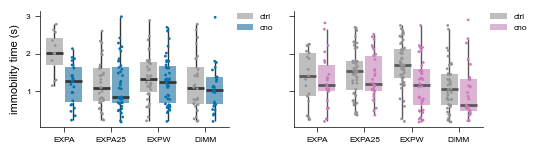

--- NTSR ---
EXPA 0.0007883287032760171
EXPA25 0.68071485240964
EXPW 0.3928944817725839
DIMM 0.6304183284416938
--- GRP ---
EXPA 0.5904383990296833
EXPA25 0.37145797291301574
EXPW 0.000637479428529186
DIMM 0.1797155032778187


In [29]:
from scipy.stats import ks_2samp, mannwhitneyu

# Add freeze times to dataframe
df_GRP_CNO_list = []
for stim_idx, stim_type in enumerate(stim_types_plotting):
    df_GRP_CNO_stim = pd.DataFrame.from_dict({'stim_type': [stim_type]*len(GRP_CNO_freeze_time[stim_idx]), 'freeze_time': GRP_CNO_freeze_time[stim_idx], 'condition': ['cno']*len(GRP_CNO_freeze_time[stim_idx]), 'CT': ['GRP']*len(GRP_CNO_freeze_time[stim_idx])})
    df_GRP_CNO_list.append(df_GRP_CNO_stim)
df_GRP_CNO = pd.concat(df_GRP_CNO_list).reset_index(drop=True)

df_GRP_CTRL_list = []
for stim_idx, stim_type in enumerate(stim_types_plotting):
    df_GRP_CTRL_stim = pd.DataFrame.from_dict({'stim_type': [stim_type]*len(GRP_CTRL_freeze_time[stim_idx]), 'freeze_time': GRP_CTRL_freeze_time[stim_idx], 'condition': ['ctrl']*len(GRP_CTRL_freeze_time[stim_idx]), 'CT': ['GRP']*len(GRP_CTRL_freeze_time[stim_idx])})
    df_GRP_CTRL_list.append(df_GRP_CTRL_stim)
df_GRP_CTRL = pd.concat(df_GRP_CTRL_list).reset_index(drop=True)

df_NTSR_CNO_list = []
for stim_idx, stim_type in enumerate(stim_types_plotting):
    df_NTSR_CNO_stim = pd.DataFrame.from_dict({'stim_type': [stim_type]*len(NTSR_CNO_freeze_time[stim_idx]), 'freeze_time': NTSR_CNO_freeze_time[stim_idx], 'condition': ['cno']*len(NTSR_CNO_freeze_time[stim_idx]), 'CT': ['NTSR']*len(NTSR_CNO_freeze_time[stim_idx])})
    df_NTSR_CNO_list.append(df_NTSR_CNO_stim)
df_NTSR_CNO = pd.concat(df_NTSR_CNO_list).reset_index(drop=True)

df_NTSR_CTRL_list = []
for stim_idx, stim_type in enumerate(stim_types_plotting):
    df_NTSR_CTRL_stim = pd.DataFrame.from_dict({'stim_type': [stim_type]*len(NTSR_CTRL_freeze_time[stim_idx]), 'freeze_time': NTSR_CTRL_freeze_time[stim_idx], 'condition': ['ctrl']*len(NTSR_CTRL_freeze_time[stim_idx]), 'CT': ['NTSR']*len(NTSR_CTRL_freeze_time[stim_idx])})
    df_NTSR_CTRL_list.append(df_NTSR_CTRL_stim)
df_NTSR_CTRL = pd.concat(df_NTSR_CTRL_list).reset_index(drop=True)

df = pd.concat([df_GRP_CNO, df_GRP_CTRL, df_NTSR_CNO, df_NTSR_CTRL]).reset_index(drop=True)
df['freeze_time'] = df['freeze_time']/60 # Convert to seconds
# Visualize df as boxplots using seaborn
fig, axs = plt.subplots(1,2, figsize=(14*cm, 4*cm), sharey=True)
# sb.violinplot(data=df[df['CT']=='NTSR'], y='freeze_time', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[0], palette=[color_CTRL, color_NTSR], split=True, inner="quart", fill=False, cut=0)
# sb.violinplot(data=df[df['CT']=='GRP'], y='freeze_time', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[1], palette=[color_CTRL, color_GRP], split=True, inner="quart", fill=False, cut=0)
sb.boxplot(data=df[df['CT']=='NTSR'], y='freeze_time', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[0], gap=0.1, palette=[color_CTRL, color_NTSR], showfliers=False, width=0.8, boxprops=dict(alpha=0.6, linewidth=0), medianprops=dict(linewidth=2, alpha=1), capprops=dict(linewidth=0))
sb.boxplot(data=df[df['CT']=='GRP'], y='freeze_time', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[1], gap=0.1, palette=[color_CTRL, color_GRP], showfliers=False, width=0.8, boxprops=dict(alpha=0.6, linewidth=0), medianprops=dict(linewidth=2,alpha=1), capprops=dict(linewidth=0))
# sb.pointplot(data=df[df['CT']=='NTSR'], y='peak_speed', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[0], palette=[color_CTRL, color_NTSR], dodge=0.2, join=False, estimator=np.median, errorbar=get_percentiles)
# sb.pointplot(data=df[df['CT']=='GRP'], y='peak_speed', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[1], palette=[color_CTRL, color_GRP], dodge=0.2, join=False, estimator=np.median, errorbar=get_percentiles)
sb.stripplot(data=df[df['CT']=='NTSR'], y='freeze_time', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[0], palette=[color_CTRL, color_NTSR], dodge=True, size=2, alpha=1, legend=False)
sb.stripplot(data=df[df['CT']=='GRP'], y='freeze_time', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[1], palette=[color_CTRL, color_GRP], dodge=True, size=2, alpha=1, legend=False)

# sb.violinplot(data=df[df['CT']=='NTSR'], y='freeze_time', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[0], palette=[color_CTRL, color_NTSR], split=True, inner="quart", fill=False, cut=0)
# sb.violinplot(data=df[df['CT']=='GRP'], y='freeze_time', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[1], palette=[color_CTRL, color_GRP], split=True, inner="quart", fill=False, cut=0)
# sb.swarmplot(data=df[df['CT']=='NTSR'], y='freeze_time', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[0], palette=[color_CTRL, color_NTSR], size=3, dodge=True)
# sb.swarmplot(data=df[df['CT']=='GRP'], y='freeze_time', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[1], palette=[color_CTRL, color_GRP], size=3, dodge=True)
# Remove border around legend
axs[0].legend(bbox_to_anchor=(1, 1.05), frameon=False);''

axs[0].set(xlabel='', ylabel='immobility time (s)')
axs[1].legend(bbox_to_anchor=(1, 1.05), frameon=False)
axs[1].set(xlabel='')
plt.tight_layout()
plt.savefig(os.path.join(fig_path, 'fig1_inhibition_immobilitytime_v2.pdf'), bbox_inches='tight')
plt.show()

print("--- NTSR ---")
for stim_type, stim_label in zip(stim_types_plotting, stim_types_plotting_labels):
    freeze_time_cno = df[(df['CT']=='NTSR')&(df['stim_type']==stim_type)&(df['condition']=='cno')]['freeze_time']
    freeze_time_ctrl = df[(df['CT']=='NTSR')&(df['stim_type']==stim_type)&(df['condition']=='ctrl')]['freeze_time']
    # print(stim_type, ks_2samp(freeze_time_cno, freeze_time_ctrl).pvalue)
    print(stim_type, mannwhitneyu(freeze_time_cno, freeze_time_ctrl).pvalue)
print("--- GRP ---")
for stim_type, stim_label in zip(stim_types_plotting, stim_types_plotting_labels):
    freeze_time_cno = df[(df['CT']=='GRP')&(df['stim_type']==stim_type)&(df['condition']=='cno')]['freeze_time']
    freeze_time_ctrl = df[(df['CT']=='GRP')&(df['stim_type']==stim_type)&(df['condition']=='ctrl')]['freeze_time']
    # print(stim_type, ks_2samp(freeze_time_cno, freeze_time_ctrl).pvalue)
    print(stim_type, mannwhitneyu(freeze_time_cno, freeze_time_ctrl).pvalue)

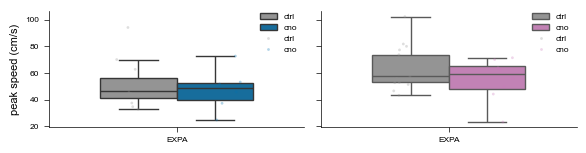

--- NTSR ---
EXPA 0.9635854341736694
--- GRP ---
EXPA 0.34399833576034944


In [28]:
def get_percentiles(x):
    return np.percentile(x, [25, 75])
stim_types_peak_speed = ['EXPA']
stim_types_peak_speed_labels = ['EXPA']

df_GRP_CNO_list = []
for stim_idx, stim_type in enumerate(stim_types_peak_speed):
    df_GRP_CNO_stim = pd.DataFrame.from_dict({'stim_type': [stim_type]*len(GRP_CNO_max_speeds[stim_idx]), 'peak_speed': GRP_CNO_max_speeds[stim_idx], 'condition': ['cno']*len(GRP_CNO_max_speeds[stim_idx]), 'CT': ['GRP']*len(GRP_CNO_max_speeds[stim_idx])})
    df_GRP_CNO_list.append(df_GRP_CNO_stim)
df_GRP_CNO = pd.concat(df_GRP_CNO_list).reset_index(drop=True)

df_GRP_CTRL_list = []
for stim_idx, stim_type in enumerate(stim_types_peak_speed):
    df_GRP_CTRL_stim = pd.DataFrame.from_dict({'stim_type': [stim_type]*len(GRP_CTRL_max_speeds[stim_idx]), 'peak_speed': GRP_CTRL_max_speeds[stim_idx], 'condition': ['ctrl']*len(GRP_CTRL_max_speeds[stim_idx]), 'CT': ['GRP']*len(GRP_CTRL_max_speeds[stim_idx])})
    df_GRP_CTRL_list.append(df_GRP_CTRL_stim)
df_GRP_CTRL = pd.concat(df_GRP_CTRL_list).reset_index(drop=True)

df_NTSR_CNO_list = []
for stim_idx, stim_type in enumerate(stim_types_peak_speed):
    df_NTSR_CNO_stim = pd.DataFrame.from_dict({'stim_type': [stim_type]*len(NTSR_CNO_max_speeds[stim_idx]), 'peak_speed': NTSR_CNO_max_speeds[stim_idx], 'condition': ['cno']*len(NTSR_CNO_max_speeds[stim_idx]), 'CT': ['NTSR']*len(NTSR_CNO_max_speeds[stim_idx])})
    df_NTSR_CNO_list.append(df_NTSR_CNO_stim)
df_NTSR_CNO = pd.concat(df_NTSR_CNO_list).reset_index(drop=True)

df_NTSR_CTRL_list = []
for stim_idx, stim_type in enumerate(stim_types_peak_speed):
    df_NTSR_CTRL_stim = pd.DataFrame.from_dict({'stim_type': [stim_type]*len(NTSR_CTRL_max_speeds[stim_idx]), 'peak_speed': NTSR_CTRL_max_speeds[stim_idx], 'condition': ['ctrl']*len(NTSR_CTRL_max_speeds[stim_idx]), 'CT': ['NTSR']*len(NTSR_CTRL_max_speeds[stim_idx])})
    df_NTSR_CTRL_list.append(df_NTSR_CTRL_stim)
df_NTSR_CTRL = pd.concat(df_NTSR_CTRL_list).reset_index(drop=True)

df_peak_speed = pd.concat([df_GRP_CNO, df_GRP_CTRL, df_NTSR_CNO, df_NTSR_CTRL]).reset_index(drop=True)
# df_peak_speed = df_peak_speed[df_peak_speed['peak_speed']<=25] # Above this number is impossible
df_peak_speed['peak_speed'] = df_peak_speed['peak_speed']*4 # Convert to cm/seconds

# Visualize df as boxplots using seaborn
fig, axs = plt.subplots(1,2, figsize=(15*cm, 4*cm), sharey=True)
sb.boxplot(data=df_peak_speed[df_peak_speed['CT']=='NTSR'], y='peak_speed', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[0], palette=[color_CTRL, color_NTSR], showfliers=False, width=0.6)
sb.boxplot(data=df_peak_speed[df_peak_speed['CT']=='GRP'], y='peak_speed', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[1], palette=[color_CTRL, color_GRP], showfliers=False, width=0.6)
# sb.pointplot(data=df[df['CT']=='NTSR'], y='peak_speed', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[0], palette=[color_CTRL, color_NTSR], dodge=0.2, join=False, estimator=np.median, errorbar=get_percentiles)
# sb.pointplot(data=df[df['CT']=='GRP'], y='peak_speed', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[1], palette=[color_CTRL, color_GRP], dodge=0.2, join=False, estimator=np.median, errorbar=get_percentiles)
sb.stripplot(data=df_peak_speed[df_peak_speed['CT']=='NTSR'], y='peak_speed', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[0], palette=[color_CTRL, color_NTSR], dodge=0.1, size=2, alpha=0.3)
sb.stripplot(data=df_peak_speed[df_peak_speed['CT']=='GRP'], y='peak_speed', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[1], palette=[color_CTRL, color_GRP], dodge=0.1, size=2, alpha=0.3)
# sb.violinplot(data=df[df['CT']=='NTSR'], y='peak_speed', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[0], palette=[color_CTRL, color_NTSR], split=True, inner="quart", fill=False, cut=0)
# sb.violinplot(data=df[df['CT']=='GRP'], y='peak_speed', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[1], palette=[color_CTRL, color_GRP], split=True, inner="quart", fill=False, cut=0)
# sb.swarmplot(data=df[df['CT']=='NTSR'], y='freeze_time', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[0], palette=[color_CTRL, color_NTSR], size=3, dodge=True)
# sb.swarmplot(data=df[df['CT']=='GRP'], y='freeze_time', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[1], palette=[color_CTRL, color_GRP], size=3, dodge=True)

# Remove border around legend
axs[0].legend(bbox_to_anchor=(1, 1.05), frameon=False)
axs[0].set(xlabel='', ylabel='peak speed (cm/s)')
axs[1].legend(bbox_to_anchor=(1, 1.05), frameon=False)
axs[1].set(xlabel='')
plt.tight_layout()
# plt.savefig(os.path.join(fig_path, 'fig1_inhibition_peakspeed.pdf'), bbox_inches='tight')
plt.show()

# Add MWU statistics
print("--- NTSR ---")
for stim_type, stim_label in zip(stim_types_peak_speed, stim_types_peak_speed_labels):
    peak_speed_cno = df_peak_speed[(df_peak_speed['CT']=='NTSR')&(df_peak_speed['stim_type']==stim_type)&(df_peak_speed['condition']=='cno')]['peak_speed']
    peak_speed_ctrl = df_peak_speed[(df_peak_speed['CT']=='NTSR')&(df_peak_speed['stim_type']==stim_type)&(df_peak_speed['condition']=='ctrl')]['peak_speed']
    # print(stim_type, ks_2samp(freeze_time_cno, freeze_time_ctrl).pvalue)
    print(stim_type, mannwhitneyu(peak_speed_cno, peak_speed_ctrl).pvalue)
print("--- GRP ---")
for stim_type, stim_label in zip(stim_types_peak_speed, stim_types_peak_speed_labels):
    peak_speed_cno = df_peak_speed[(df_peak_speed['CT']=='GRP')&(df_peak_speed['stim_type']==stim_type)&(df_peak_speed['condition']=='cno')]['peak_speed']
    peak_speed_ctrl = df_peak_speed[(df_peak_speed['CT']=='GRP')&(df_peak_speed['stim_type']==stim_type)&(df_peak_speed['condition']=='ctrl')]['peak_speed']
    # print(stim_type, ks_2samp(freeze_time_cno, freeze_time_ctrl).pvalue)
    print(stim_type, mannwhitneyu(peak_speed_cno, peak_speed_ctrl).pvalue)


meta NOT subset; don't know how to subset; dropped


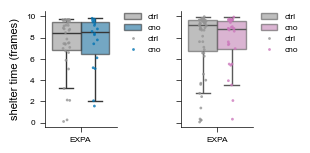

--- NTSR ---
EXPA 0.8436440581023096
--- GRP ---
EXPA 0.619898627610197


In [29]:
# Time spent in shelter after escapes
def get_percentiles(x):
    return np.percentile(x, [25, 75])
stim_types_peak_speed = ['EXPA']
stim_types_peak_speed_labels = ['EXPA']

df_GRP_CNO_list = []
for stim_idx, stim_type in enumerate(stim_types_peak_speed):
    df_GRP_CNO_stim = pd.DataFrame.from_dict({'stim_type': [stim_type]*len(GRP_CNO_shelter_time[stim_idx]), 'shelter_time': GRP_CNO_shelter_time[stim_idx], 'condition': ['cno']*len(GRP_CNO_shelter_time[stim_idx]), 'CT': ['GRP']*len(GRP_CNO_shelter_time[stim_idx])})
    df_GRP_CNO_list.append(df_GRP_CNO_stim)
df_GRP_CNO = pd.concat(df_GRP_CNO_list).reset_index(drop=True)

df_GRP_CTRL_list = []
for stim_idx, stim_type in enumerate(stim_types_peak_speed):
    df_GRP_CTRL_stim = pd.DataFrame.from_dict({'stim_type': [stim_type]*len(GRP_CTRL_shelter_time[stim_idx]), 'shelter_time': GRP_CTRL_shelter_time[stim_idx], 'condition': ['ctrl']*len(GRP_CTRL_shelter_time[stim_idx]), 'CT': ['GRP']*len(GRP_CTRL_shelter_time[stim_idx])})
    df_GRP_CTRL_list.append(df_GRP_CTRL_stim)
df_GRP_CTRL = pd.concat(df_GRP_CTRL_list).reset_index(drop=True)

df_NTSR_CNO_list = []
for stim_idx, stim_type in enumerate(stim_types_peak_speed):
    df_NTSR_CNO_stim = pd.DataFrame.from_dict({'stim_type': [stim_type]*len(NTSR_CNO_shelter_time[stim_idx]), 'shelter_time': NTSR_CNO_shelter_time[stim_idx], 'condition': ['cno']*len(NTSR_CNO_shelter_time[stim_idx]), 'CT': ['NTSR']*len(NTSR_CNO_shelter_time[stim_idx])})
    df_NTSR_CNO_list.append(df_NTSR_CNO_stim)
df_NTSR_CNO = pd.concat(df_NTSR_CNO_list).reset_index(drop=True)

df_NTSR_CTRL_list = []
for stim_idx, stim_type in enumerate(stim_types_peak_speed):
    df_NTSR_CTRL_stim = pd.DataFrame.from_dict({'stim_type': [stim_type]*len(NTSR_CTRL_shelter_time[stim_idx]), 'shelter_time': NTSR_CTRL_shelter_time[stim_idx], 'condition': ['ctrl']*len(NTSR_CTRL_shelter_time[stim_idx]), 'CT': ['NTSR']*len(NTSR_CTRL_shelter_time[stim_idx])})
    df_NTSR_CTRL_list.append(df_NTSR_CTRL_stim)
df_NTSR_CTRL = pd.concat(df_NTSR_CTRL_list).reset_index(drop=True)

df_shelter_time = pd.concat([df_GRP_CNO, df_GRP_CTRL, df_NTSR_CNO, df_NTSR_CTRL]).reset_index(drop=True)
# df = df[df['peak_speed']<=25] # Above this number is impossible
# df['peak_speed'] = df['peak_speed']*4 # Convert to cm/seconds

# Visualize df as boxplots using seaborn
fig, axs = plt.subplots(1,2, figsize=(8*cm, 4*cm), sharey=True)
sb.boxplot(data=df_shelter_time[df_shelter_time['CT']=='NTSR'], y='shelter_time', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[0], palette=[color_CTRL, color_NTSR], showfliers=False, width=0.8, boxprops=dict(alpha=0.6))
sb.boxplot(data=df_shelter_time[df_shelter_time['CT']=='GRP'], y='shelter_time', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[1], palette=[color_CTRL, color_GRP], showfliers=False, width=0.8, boxprops=dict(alpha=0.6))
# sb.pointplot(data=df[df['CT']=='NTSR'], y='peak_speed', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[0], palette=[color_CTRL, color_NTSR], dodge=0.2, join=False, estimator=np.median, errorbar=get_percentiles)
# sb.pointplot(data=df[df['CT']=='GRP'], y='peak_speed', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[1], palette=[color_CTRL, color_GRP], dodge=0.2, join=False, estimator=np.median, errorbar=get_percentiles)
sb.stripplot(data=df_shelter_time[df_shelter_time['CT']=='NTSR'], y='shelter_time', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[0], palette=[color_CTRL, color_NTSR], dodge=True, size=2, alpha=0.8)
sb.stripplot(data=df_shelter_time[df_shelter_time['CT']=='GRP'], y='shelter_time', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[1], palette=[color_CTRL, color_GRP], dodge=True, size=2, alpha=0.8)
# sb.violinplot(data=df[df['CT']=='NTSR'], y='peak_speed', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[0], palette=[color_CTRL, color_NTSR], split=True, inner="quart", fill=False, cut=0)
# sb.violinplot(data=df[df['CT']=='GRP'], y='peak_speed', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[1], palette=[color_CTRL, color_GRP], split=True, inner="quart", fill=False, cut=0)
# sb.swarmplot(data=df[df['CT']=='NTSR'], y='freeze_time', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[0], palette=[color_CTRL, color_NTSR], size=3, dodge=True)
# sb.swarmplot(data=df[df['CT']=='GRP'], y='freeze_time', x='stim_type', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[1], palette=[color_CTRL, color_GRP], size=3, dodge=True)

# Remove border around legend
axs[0].legend(bbox_to_anchor=(1, 1.05), frameon=False)
axs[0].set(xlabel='', ylabel='shelter time (frames)')
axs[1].legend(bbox_to_anchor=(1, 1.05), frameon=False)
axs[1].set(xlabel='')
plt.tight_layout()
plt.savefig(os.path.join(fig_path, 'fig1_inhibition_shelter_time.pdf'), bbox_inches='tight')
plt.show()

# Add MWU statistics
print("--- NTSR ---")
for stim_type, stim_label in zip(stim_types_peak_speed, stim_types_peak_speed_labels):
    peak_speed_cno = df_shelter_time[(df_shelter_time['CT']=='NTSR')&(df_shelter_time['stim_type']==stim_type)&(df_shelter_time['condition']=='cno')]['shelter_time']
    peak_speed_ctrl = df_shelter_time[(df_shelter_time['CT']=='NTSR')&(df_shelter_time['stim_type']==stim_type)&(df_shelter_time['condition']=='ctrl')]['shelter_time']
    # print(stim_type, ks_2samp(freeze_time_cno, freeze_time_ctrl).pvalue)
    print(stim_type, mannwhitneyu(peak_speed_cno, peak_speed_ctrl).pvalue)
print("--- GRP ---")
for stim_type, stim_label in zip(stim_types_peak_speed, stim_types_peak_speed_labels):
    peak_speed_cno = df_shelter_time[(df_shelter_time['CT']=='GRP')&(df_shelter_time['stim_type']==stim_type)&(df_shelter_time['condition']=='cno')]['shelter_time']
    peak_speed_ctrl = df_shelter_time[(df_shelter_time['CT']=='GRP')&(df_shelter_time['stim_type']==stim_type)&(df_shelter_time['condition']=='ctrl')]['shelter_time']
    # print(stim_type, ks_2samp(freeze_time_cno, freeze_time_ctrl).pvalue)
    print(stim_type, mannwhitneyu(peak_speed_cno, peak_speed_ctrl).pvalue)


4
4


meta NOT subset; don't know how to subset; dropped


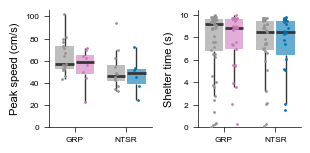

--- NTSR ---
EXPA 0.9635854341736694 N: 6 12
EXPA 0.8436440581023096 N: 18 35
--- GRP ---
EXPA 0.34399833576034944 N: 8 17
EXPA 0.619898627610197 N: 29 56


In [30]:
# # Combine peak speed and shelter time (of escapes) into a single plot
# df_peak_speed['group'] = df_peak_speed['CT'] + '_' + df_peak_speed['condition']
# df_shelter_time['group'] = df_shelter_time['CT'] + '_' + df_shelter_time['condition']
# # 2. Create the palette dictionary
# my_palette = {
#     'GRP_ctrl': color_CTRL,
#     'GRP_cno': color_GRP,
#     'NTSR_ctrl': color_CTRL,
#     'NTSR_cno': color_NTSR
# }

fig, axs = plt.subplots(1,2, figsize=(8*cm, 4*cm), sharey=False)
sb.boxplot(data=df_peak_speed, y='peak_speed', x='CT', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[0], gap=0.1, palette=[color_CTRL, color_NTSR], showfliers=False, width=0.8, boxprops=dict(alpha=0.6, linewidth=0), medianprops=dict(linewidth=2, alpha=1), capprops=dict(linewidth=0))
sb.stripplot(data=df_peak_speed, y='peak_speed', x='CT', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[0], palette=[color_CTRL, color_NTSR], dodge=True, size=2, alpha=1)

sb.boxplot(data=df_shelter_time, y='shelter_time', x='CT', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[1], gap=0.1, palette=[color_CTRL, color_NTSR], showfliers=False, width=0.8, boxprops=dict(alpha=0.6, linewidth=0), medianprops=dict(linewidth=2, alpha=1), capprops=dict(linewidth=0))
sb.stripplot(data=df_shelter_time, y='shelter_time', x='CT', hue='condition', hue_order=['ctrl', 'cno'], ax=axs[1], palette=[color_CTRL, color_NTSR], dodge=True, size=2, alpha=1)

# remove legend
axs[0].legend().remove()
axs[1].legend().remove()

box_colors = [color_CTRL, color_CTRL, color_GRP, color_NTSR,color_CTRL,color_CTRL]
for i, ax in enumerate(axs):
    # --- Re-color the box plots (artists) ---
    boxes = ax.patches
    for j, box in enumerate(boxes):
        box.set_facecolor(box_colors[j])
        
    # --- Re-color the scatter points (collections) ---
    collections = ax.collections
    scatter_colors = [color_CTRL, color_GRP, color_CTRL, color_NTSR,color_CTRL,color_CTRL]
    print(len(collections))
    for j, collection in enumerate(collections):
        collection.set_facecolor(scatter_colors[j])
        collection.set_edgecolor(scatter_colors[j]) # Also set edge color

# Remove border around legend
# axs[0].legend(bbox_to_anchor=(1, 1.05), frameon=False)
axs[0].set(xlabel='', ylabel='Peak speed (cm/s)', ylim=(0, None))
# axs[1].legend(bbox_to_anchor=(1, 1.05), frameon=False)
axs[1].set(xlabel='', ylabel='Shelter time (s)', ylim=(0, None))
plt.tight_layout()
plt.savefig(os.path.join(fig_path, 'fig1_inhibition_escapemeasures.pdf'), bbox_inches='tight')
plt.show()

# Add MWU statistics
print("--- NTSR ---")
for stim_type, stim_label in zip(stim_types_peak_speed, stim_types_peak_speed_labels):
    peak_speed_cno = df_peak_speed[(df_peak_speed['CT']=='NTSR')&(df_peak_speed['stim_type']==stim_type)&(df_peak_speed['condition']=='cno')]['peak_speed']
    peak_speed_ctrl = df_peak_speed[(df_peak_speed['CT']=='NTSR')&(df_peak_speed['stim_type']==stim_type)&(df_peak_speed['condition']=='ctrl')]['peak_speed']
    shelter_time_cno = df_shelter_time[(df_shelter_time['CT']=='NTSR')&(df_shelter_time['stim_type']==stim_type)&(df_shelter_time['condition']=='cno')]['shelter_time']
    shelter_time_ctrl = df_shelter_time[(df_shelter_time['CT']=='NTSR')&(df_shelter_time['stim_type']==stim_type)&(df_shelter_time['condition']=='ctrl')]['shelter_time']
    # print(stim_type, ks_2samp(freeze_time_cno, freeze_time_ctrl).pvalue)
    print(stim_type, mannwhitneyu(peak_speed_cno, peak_speed_ctrl).pvalue, "N:", len(peak_speed_cno), len(peak_speed_ctrl))
    print(stim_type, mannwhitneyu(shelter_time_cno, shelter_time_ctrl).pvalue, "N:", len(shelter_time_cno), len(shelter_time_ctrl))
print("--- GRP ---")
for stim_type, stim_label in zip(stim_types_peak_speed, stim_types_peak_speed_labels):
    peak_speed_cno = df_peak_speed[(df_peak_speed['CT']=='GRP')&(df_peak_speed['stim_type']==stim_type)&(df_peak_speed['condition']=='cno')]['peak_speed']
    peak_speed_ctrl = df_peak_speed[(df_peak_speed['CT']=='GRP')&(df_peak_speed['stim_type']==stim_type)&(df_peak_speed['condition']=='ctrl')]['peak_speed']
    shelter_time_cno = df_shelter_time[(df_shelter_time['CT']=='GRP')&(df_shelter_time['stim_type']==stim_type)&(df_shelter_time['condition']=='cno')]['shelter_time']
    shelter_time_ctrl = df_shelter_time[(df_shelter_time['CT']=='GRP')&(df_shelter_time['stim_type']==stim_type)&(df_shelter_time['condition']=='ctrl')]['shelter_time']
    # print(stim_type, ks_2samp(freeze_time_cno, freeze_time_ctrl).pvalue)
    print(stim_type, mannwhitneyu(peak_speed_cno, peak_speed_ctrl).pvalue, "N:", len(peak_speed_cno), len(peak_speed_ctrl))
    print(stim_type, mannwhitneyu(shelter_time_cno, shelter_time_ctrl).pvalue, "N:", len(shelter_time_cno), len(shelter_time_ctrl))


### Statistics
- Standard stats (two-sided Kolmogorov–Smirnov)
- Linear Mixed Effects Model
- Hierarchical bootstrapping

In [12]:
GRP_CNO_dict_speed_mat = []
GRP_CNO_dict_etho_mat = []
for stim_type, stim_label in zip(stim_types_plotting, stim_types_plotting_labels):
    GRP_CNO_dict_speed_mat.append(np.concatenate([value for value in GRP_CNO_dict_speed[stim_type].values()], axis=0))
    GRP_CNO_dict_etho_mat.append(np.concatenate([value for value in GRP_CNO_dict_etho[stim_type].values()], axis=0))
GRP_CTRL_dict_speed_mat = []
GRP_CTRL_dict_etho_mat = []
for stim_type, stim_label in zip(stim_types_plotting, stim_types_plotting_labels):
    GRP_CTRL_dict_speed_mat.append(np.concatenate([value for value in GRP_CTRL_dict_speed[stim_type].values()], axis=0))
    GRP_CTRL_dict_etho_mat.append(np.concatenate([value for value in GRP_CTRL_dict_etho[stim_type].values()], axis=0))

NTSR_CNO_dict_speed_mat = []
NTSR_CNO_dict_etho_mat = []
for stim_type, stim_label in zip(stim_types_plotting, stim_types_plotting_labels):
    NTSR_CNO_dict_speed_mat.append(np.concatenate([value for value in NTSR_CNO_dict_speed[stim_type].values()], axis=0))
    NTSR_CNO_dict_etho_mat.append(np.concatenate([value for value in NTSR_CNO_dict_etho[stim_type].values()], axis=0))
NTSR_CTRL_dict_speed_mat = []
NTSR_CTRL_dict_etho_mat = []
for stim_type, stim_label in zip(stim_types_plotting, stim_types_plotting_labels):
    NTSR_CTRL_dict_speed_mat.append(np.concatenate([value for value in NTSR_CTRL_dict_speed[stim_type].values()], axis=0))
    NTSR_CTRL_dict_etho_mat.append(np.concatenate([value for value in NTSR_CTRL_dict_etho[stim_type].values()], axis=0))

In [349]:
def get_data_dict(stim_types_plotting, speed_dict, etho_dict):
    data_dict = {'stim_type': [], 'mouse_key': [], 'escape': [], 'trial': [], 'onset_speed': [], 'session_id': []}
    for stim_type in stim_types_plotting:
        for key, etho_mat in etho_dict[stim_type].items():
            trials_behavior = np.any(etho_mat[:,300:480]==1, axis=1)
            trials_speed = speed_dict[stim_type][key]
            for trial_idx, (trial, speed) in enumerate(zip(trials_behavior, trials_speed)):
                data_dict['stim_type'].append(stim_type)
                data_dict['mouse_key'].append(f'{key[0]}')# _{key[1]}_{key[2]}
                data_dict['escape'].append(trial)
                data_dict['onset_speed'].append(np.mean(speed[270:300])) # 0.5 seconds before stimulus onset
                # data_dict['shelter_dist'] = ...
                data_dict['session_id'].append(key[2])
                data_dict['trial'].append(trial_idx)
            # pass
    return pd.DataFrame.from_dict(data_dict)

GRP_CNO_df = get_data_dict(stim_types_plotting, GRP_CNO_dict_speed, GRP_CNO_dict_etho)
GRP_CNO_df['condition'] = 'cno'
GRP_CNO_df['group'] = 'GRP'

GRP_CTRL_df = get_data_dict(stim_types_plotting, GRP_CTRL_dict_speed, GRP_CTRL_dict_etho)
GRP_CTRL_df['condition'] = 'ctrl'
GRP_CTRL_df['group'] = 'GRP'

NTSR_CNO_df = get_data_dict(stim_types_plotting, NTSR_CNO_dict_speed, NTSR_CNO_dict_etho)
NTSR_CNO_df['condition'] = 'cno'
NTSR_CNO_df['group'] = 'NTSR'

NTSR_CTRL_df = get_data_dict(stim_types_plotting, NTSR_CTRL_dict_speed, NTSR_CTRL_dict_etho)
NTSR_CTRL_df['condition'] = 'ctrl'
NTSR_CTRL_df['group'] = 'NTSR'


# GRP_df = pd.concat([GRP_CNO_df, GRP_CTRL_df, NTSR_CTRL_df])
# NTSR_df = pd.concat([NTSR_CNO_df, GRP_CTRL_df, NTSR_CTRL_df])

GRP_df = pd.concat([GRP_CNO_df, GRP_CTRL_df, NTSR_CTRL_df])
NTSR_df = pd.concat([NTSR_CNO_df, GRP_CTRL_df, NTSR_CTRL_df])
df_comb = pd.concat([NTSR_CNO_df, GRP_CTRL_df, NTSR_CTRL_df])

# df.to_csv('/Users/bramn/Documents/Projects/DJOpenfield/data/processed/CoordinatedCellTypes/fig1_inhibition.csv')

In [ ]:
GRP_df['escape']  = GRP_df['escape'].astype(int)
NTSR_df['escape'] = NTSR_df['escape'].astype(int)
df_comb['escape'] = df_comb['escape'].astype(int)

In [366]:

def plot_marginal_probabilities(df, stim_type, group_name, condition_col='condition', fig_path=None):
    fig, ax = plt.subplots(figsize=(3.5*cm, 4*cm))
    
    # 1. Calculate raw subject-level averages
    mouse_means = df.groupby([condition_col, 'mouse_key'])['escape'].mean().reset_index()
    
    # EXPLICIT ORDER: This prevents seaborn from sorting alphabetically
    plot_order = ['ctrl', 'cno']
    
    # 2. Plot the raw subject-level data
    sns.stripplot(data=mouse_means, x=condition_col, y='escape', 
                  order=plot_order, # <-- ADDED
                  color='gray', alpha=0.5, jitter=0.1, size=2, zorder=1, ax=ax)
    
    # 3. Calculate and plot the group-level means with error bars
    sns.pointplot(data=mouse_means, x=condition_col, y='escape', 
                  order=plot_order, # <-- ADDED
                  color='black', errorbar=('ci', 95), 
                  markers="o", scale=1.2, errwidth=2, capsize=0.1, zorder=2, ax=ax)
    
    # 4. Formatting
    ax.set_ylim(-0.05, 1.05)
    ax.set_ylabel('Escape probability')
    ax.set_xlabel('')
    
    # Now that 'ctrl' is forced to the left, this label assignment is safe and correct
    ax.set_xticklabels(['Control', 'CNO']) 
    
    sns.despine(ax=ax)
    plt.tight_layout()
    if fig_path:
        plt.savefig(os.path.join(fig_path, f'prob_escape_mice_{group_name}_{stim_type}.pdf'), dpi=300)
    plt.show()

import numpy as np
import os

import numpy as np
import os

def save_model_stats_txt(model, filename):
    """
    Extracts statistics from a fitted pymer4 model, calculates Odds Ratios 
    (if binomial), reorders the columns, and saves to a tab-separated TXT file.
    """
    # Extract the base coefficients dataframe from pymer4
    results_df = model.coefs.copy()
    
    # If the model is a logistic mixed model, calculate Odds Ratios
    if model.family == 'binomial':
        results_df['OR'] = np.exp(results_df['Estimate'])
        results_df['OR_2.5_ci'] = np.exp(results_df['2.5_ci'])
        results_df['OR_97.5_ci'] = np.exp(results_df['97.5_ci'])
        
        ordered_cols = ['Estimate', '2.5_ci', '97.5_ci', 'SE', 'OR', 'OR_2.5_ci', 'OR_97.5_ci', 'Z-stat', 'P-val', 'Sig']
    else:
        ordered_cols = ['Estimate', '2.5_ci', '97.5_ci', 'SE', 'T-stat', 'P-val', 'Sig']
        
    # Reorder columns
    cols = results_df.columns.tolist()
    results_df = results_df[[c for c in ordered_cols if c in cols]]
    
    # Create the directory safely if it doesn't exist
    directory = os.path.dirname(filename)
    if directory:
        os.makedirs(directory, exist_ok=True)
        
    # Save to TXT using a tab separator ('\t')
    results_df.to_csv(filename, sep='\t', index=True)
    print(f"Stats successfully saved to: {filename}")
    
    return results_df

Linear mixed model fit by maximum likelihood  ['lmerMod']
Formula: escape~C(condition)+trial+onset_speed+(1|mouse_key)

Family: binomial	 Inference: parametric

Number of observations: 175	 Groups: {'mouse_key': 39.0}

Log-likelihood: -89.190 	 AIC: 188.381

Random effects:

                  Name    Var    Std
mouse_key  (Intercept)  5.186  2.277

No random effect correlations specified

Fixed effects:

--- Model Summary ---
Linear mixed model fit by maximum likelihood  ['lmerMod']
Formula: escape~C(condition)+trial+onset_speed+(1|mouse_key)

Family: binomial	 Inference: parametric

Number of observations: 175	 Groups: {'mouse_key': 39.0}

Log-likelihood: -89.190 	 AIC: 188.381

Random effects:

                  Name    Var    Std
mouse_key  (Intercept)  5.186  2.277

No random effect correlations specified

Fixed effects:

                  Estimate  2.5_ci  97.5_ci     SE     OR  OR_2.5_ci  \
(Intercept)         -1.651  -3.588    0.287  0.989  0.192      0.028   
C(condition)ctrl  

C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:16: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(data=mouse_means, x=condition_col, y='escape',
C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:16: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 2}` instead.

  sns.pointplot(data=mouse_means, x=condition_col, y='escape',
C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:27: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(['Control', 'CNO'])
meta NOT subset; don't know how to subset; dropped


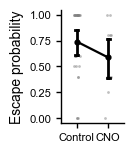

Linear mixed model fit by maximum likelihood  ['lmerMod']
Formula: escape~C(condition)+trial+onset_speed+(1|mouse_key)

Family: binomial	 Inference: parametric

Number of observations: 169	 Groups: {'mouse_key': 40.0}

Log-likelihood: -82.091 	 AIC: 174.183

Random effects:

                  Name    Var    Std
mouse_key  (Intercept)  7.496  2.738

No random effect correlations specified

Fixed effects:

--- Model Summary ---
Linear mixed model fit by maximum likelihood  ['lmerMod']
Formula: escape~C(condition)+trial+onset_speed+(1|mouse_key)

Family: binomial	 Inference: parametric

Number of observations: 169	 Groups: {'mouse_key': 40.0}

Log-likelihood: -82.091 	 AIC: 174.183

Random effects:

                  Name    Var    Std
mouse_key  (Intercept)  7.496  2.738

No random effect correlations specified

Fixed effects:

                  Estimate  2.5_ci  97.5_ci     SE      OR  OR_2.5_ci  \
(Intercept)         -2.506  -4.978   -0.034  1.261   0.082      0.007   
C(condition)ctrl

C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:16: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(data=mouse_means, x=condition_col, y='escape',
C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:16: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 2}` instead.

  sns.pointplot(data=mouse_means, x=condition_col, y='escape',
C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:27: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(['Control', 'CNO'])
meta NOT subset; don't know how to subset; dropped


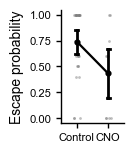

Stats successfully saved to: E:\KU Leuven\FarrowLab-Colab - VEIDB\Manuscript\Figures\Behavior\LMM_escape_mice_WF_EXPA.txt
Linear mixed model fit by maximum likelihood  ['lmerMod']
Formula: escape~C(condition)+trial+onset_speed+(1|mouse_key)

Family: binomial	 Inference: parametric

Number of observations: 170	 Groups: {'mouse_key': 39.0}

Log-likelihood: -83.544 	 AIC: 177.089

Random effects:

                  Name    Var    Std
mouse_key  (Intercept)  1.153  1.074

No random effect correlations specified

Fixed effects:

--- Model Summary ---
Linear mixed model fit by maximum likelihood  ['lmerMod']
Formula: escape~C(condition)+trial+onset_speed+(1|mouse_key)

Family: binomial	 Inference: parametric

Number of observations: 170	 Groups: {'mouse_key': 39.0}

Log-likelihood: -83.544 	 AIC: 177.089

Random effects:

                  Name    Var    Std
mouse_key  (Intercept)  1.153  1.074

No random effect correlations specified

Fixed effects:

                  Estimate  2.5_ci  97.5

C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:16: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(data=mouse_means, x=condition_col, y='escape',
C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:16: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 2}` instead.

  sns.pointplot(data=mouse_means, x=condition_col, y='escape',
C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:27: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(['Control', 'CNO'])
meta NOT subset; don't know how to subset; dropped


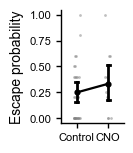

Linear mixed model fit by maximum likelihood  ['lmerMod']
Formula: escape~C(condition)+trial+onset_speed+(1|mouse_key)

Family: binomial	 Inference: parametric

Number of observations: 170	 Groups: {'mouse_key': 40.0}

Log-likelihood: -69.795 	 AIC: 149.590

Random effects:

                  Name    Var    Std
mouse_key  (Intercept)  1.644  1.282

No random effect correlations specified

Fixed effects:

--- Model Summary ---
Linear mixed model fit by maximum likelihood  ['lmerMod']
Formula: escape~C(condition)+trial+onset_speed+(1|mouse_key)

Family: binomial	 Inference: parametric

Number of observations: 170	 Groups: {'mouse_key': 40.0}

Log-likelihood: -69.795 	 AIC: 149.590

Random effects:

                  Name    Var    Std
mouse_key  (Intercept)  1.644  1.282

No random effect correlations specified

Fixed effects:

                  Estimate  2.5_ci  97.5_ci     SE     OR  OR_2.5_ci  \
(Intercept)         -5.363  -7.715   -3.010  1.200  0.005      0.000   
C(condition)ctrl  

C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:16: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(data=mouse_means, x=condition_col, y='escape',
C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:16: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 2}` instead.

  sns.pointplot(data=mouse_means, x=condition_col, y='escape',
C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:27: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(['Control', 'CNO'])
meta NOT subset; don't know how to subset; dropped


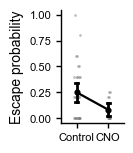

Stats successfully saved to: E:\KU Leuven\FarrowLab-Colab - VEIDB\Manuscript\Figures\Behavior\LMM_escape_mice_WF_EXPA25.txt
Linear mixed model fit by maximum likelihood  ['lmerMod']
Formula: escape~C(condition)+trial+onset_speed+(1|mouse_key)

Family: binomial	 Inference: parametric

Number of observations: 175	 Groups: {'mouse_key': 39.0}

Log-likelihood: -82.935 	 AIC: 175.869

Random effects:

                  Name    Var    Std
mouse_key  (Intercept)  2.417  1.555

No random effect correlations specified

Fixed effects:

--- Model Summary ---
Linear mixed model fit by maximum likelihood  ['lmerMod']
Formula: escape~C(condition)+trial+onset_speed+(1|mouse_key)

Family: binomial	 Inference: parametric

Number of observations: 175	 Groups: {'mouse_key': 39.0}

Log-likelihood: -82.935 	 AIC: 175.869

Random effects:

                  Name    Var    Std
mouse_key  (Intercept)  2.417  1.555

No random effect correlations specified

Fixed effects:

                  Estimate  2.5_ci  97

C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:16: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(data=mouse_means, x=condition_col, y='escape',
C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:16: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 2}` instead.

  sns.pointplot(data=mouse_means, x=condition_col, y='escape',
C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:27: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(['Control', 'CNO'])
meta NOT subset; don't know how to subset; dropped


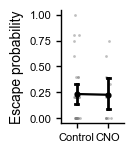

Linear mixed model fit by maximum likelihood  ['lmerMod']
Formula: escape~C(condition)+trial+onset_speed+(1|mouse_key)

Family: binomial	 Inference: parametric

Number of observations: 172	 Groups: {'mouse_key': 40.0}

Log-likelihood: -57.233 	 AIC: 124.467

Random effects:

                  Name    Var    Std
mouse_key  (Intercept)  4.704  2.169

No random effect correlations specified

Fixed effects:

--- Model Summary ---
Linear mixed model fit by maximum likelihood  ['lmerMod']
Formula: escape~C(condition)+trial+onset_speed+(1|mouse_key)

Family: binomial	 Inference: parametric

Number of observations: 172	 Groups: {'mouse_key': 40.0}

Log-likelihood: -57.233 	 AIC: 124.467

Random effects:

                  Name    Var    Std
mouse_key  (Intercept)  4.704  2.169

No random effect correlations specified

Fixed effects:

                  Estimate  2.5_ci  97.5_ci     SE      OR  OR_2.5_ci  \
(Intercept)         -8.926 -13.787   -4.065  2.480   0.000      0.000   
C(condition)ctrl

C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:16: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(data=mouse_means, x=condition_col, y='escape',
C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:16: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 2}` instead.

  sns.pointplot(data=mouse_means, x=condition_col, y='escape',
C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:27: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(['Control', 'CNO'])
meta NOT subset; don't know how to subset; dropped


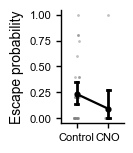

Stats successfully saved to: E:\KU Leuven\FarrowLab-Colab - VEIDB\Manuscript\Figures\Behavior\LMM_escape_mice_WF_EXPW.txt
Linear mixed model fit by maximum likelihood  ['lmerMod']
Formula: escape~C(condition)+trial+onset_speed+(1|mouse_key)

Family: binomial	 Inference: parametric

Number of observations: 181	 Groups: {'mouse_key': 39.0}

Log-likelihood: -113.356 	 AIC: 236.712

Random effects:

                  Name    Var    Std
mouse_key  (Intercept)  1.549  1.245

No random effect correlations specified

Fixed effects:

--- Model Summary ---
Linear mixed model fit by maximum likelihood  ['lmerMod']
Formula: escape~C(condition)+trial+onset_speed+(1|mouse_key)

Family: binomial	 Inference: parametric

Number of observations: 181	 Groups: {'mouse_key': 39.0}

Log-likelihood: -113.356 	 AIC: 236.712

Random effects:

                  Name    Var    Std
mouse_key  (Intercept)  1.549  1.245

No random effect correlations specified

Fixed effects:

                  Estimate  2.5_ci  97

C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:16: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(data=mouse_means, x=condition_col, y='escape',
C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:16: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 2}` instead.

  sns.pointplot(data=mouse_means, x=condition_col, y='escape',
C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:27: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(['Control', 'CNO'])
meta NOT subset; don't know how to subset; dropped


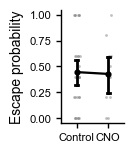

Linear mixed model fit by maximum likelihood  ['lmerMod']
Formula: escape~C(condition)+trial+onset_speed+(1|mouse_key)

Family: binomial	 Inference: parametric

Number of observations: 175	 Groups: {'mouse_key': 40.0}

Log-likelihood: -104.982 	 AIC: 219.964

Random effects:

                  Name    Var    Std
mouse_key  (Intercept)  1.781  1.335

No random effect correlations specified

Fixed effects:

--- Model Summary ---
Linear mixed model fit by maximum likelihood  ['lmerMod']
Formula: escape~C(condition)+trial+onset_speed+(1|mouse_key)

Family: binomial	 Inference: parametric

Number of observations: 175	 Groups: {'mouse_key': 40.0}

Log-likelihood: -104.982 	 AIC: 219.964

Random effects:

                  Name    Var    Std
mouse_key  (Intercept)  1.781  1.335

No random effect correlations specified

Fixed effects:

                  Estimate  2.5_ci  97.5_ci     SE     OR  OR_2.5_ci  \
(Intercept)         -2.241  -3.697   -0.784  0.743  0.106      0.025   
C(condition)ctrl

C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:16: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(data=mouse_means, x=condition_col, y='escape',
C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:16: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 2}` instead.

  sns.pointplot(data=mouse_means, x=condition_col, y='escape',
C:\Users\bramn\AppData\Local\Temp\ipykernel_23576\1247006240.py:27: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(['Control', 'CNO'])
meta NOT subset; don't know how to subset; dropped


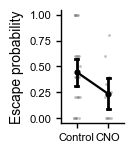

Stats successfully saved to: E:\KU Leuven\FarrowLab-Colab - VEIDB\Manuscript\Figures\Behavior\LMM_escape_mice_WF_DIMM.txt


In [367]:
from pymer4 import Lmer

formula = 'escape ~ C(condition) + trial + onset_speed + (1 | mouse_key)'

for stim_type in stim_types_plotting: # ['EXPA']
    model_GRP = Lmer(formula, data=GRP_df[GRP_df['stim_type']==stim_type].reset_index(drop=True), family='binomial')
    model_GRP.fit()
    print("--- Model Summary ---")
    print(model_GRP.summary())
    print("\n--- Confidence Intervals ---")
    print(model_GRP.confint())
    save_model_stats_txt(model_GRP, filename=os.path.join(fig_path, f'LMM_escape_mice_NF_{stim_type}.txt'))
    plot_marginal_probabilities(GRP_df[GRP_df['stim_type']==stim_type].reset_index(drop=True), stim_type=stim_type, group_name='NF', fig_path=fig_path)
    model_NTSR = Lmer(formula, data=NTSR_df[NTSR_df['stim_type']==stim_type].reset_index(drop=True), family='binomial')
    model_NTSR.fit()
    print("--- Model Summary ---")
    print(model_NTSR.summary())
    print("\n--- Confidence Intervals ---")
    print(model_NTSR.confint())
    plot_marginal_probabilities(NTSR_df[NTSR_df['stim_type']==stim_type].reset_index(drop=True), stim_type=stim_type, group_name='WF', fig_path=fig_path)
    save_model_stats_txt(model_NTSR, filename=os.path.join(fig_path, f'LMM_escape_mice_WF_{stim_type}.txt'))
